# TP1 — Análisis descriptivo y predicción de informalidad

**Machine Learning para Economistas — UdeSA, 2026**  
**Profesor:** Walter Sosa Escudero  
**Grupo:** 8

El objetivo del trabajo es analizar las características socioeconómicas asociadas a la informalidad laboral en Argentina y evaluar distintos modelos de clasificación utilizando la Encuesta Permanente de Hogares (EPH) del primer trimestre de 2026.

---

# 0. Configuración y preparación de datos

## 0.1. Importación de librerías

Se importan las librerías necesarias para manipulación de datos, visualización y descarga de archivos.

In [28]:
import pandas as pd
import numpy as np

import os
from os.path import join
from pathlib import Path
from os import makedirs, remove

import seaborn as sns
import matplotlib.pyplot as plt

import requests
import zipfile

from sklearn.model_selection import train_test_split

## 0.2. Definición de directorios

Se establece la estructura de carpetas del proyecto, diferenciando entre datos originales, resultados, programas y documentos LaTeX.

In [29]:
main_path = Path("D:/Github/PE1333_Grupo8/TP_01")

# Directorios principales
a_path = join(main_path, "A_Inputs")
b_path = join(main_path, "B_Outputs")
c_path = join(main_path, "C_Programs")
d_path = join(main_path, "D_LaTeX")

# Subdirectorios de resultados
b_path_data = join(b_path, "B_Data")
b_path_figr = join(b_path, "B_Figure")
b_path_tabl = join(b_path, "B_Table")
b_path_text = join(b_path, "B_Text")

## 0.3. Descarga e importación de datos

Se utilizan las bases de microdatos individuales y de hogares de la Encuesta Permanente de Hogares (EPH) correspondientes al primer trimestre de 2026, publicadas por el Instituto Nacional de Estadística y Censos (INDEC).

Para asegurar la reproducibilidad, se automatiza la descarga de los archivos originales desde la página del INDEC.

In [30]:
for year in [2026]:
    for trim in range(1, 2):

        url = (
            "https://www.indec.gob.ar/ftp/cuadros/menusuperior/eph/"
            f"EPH_usu_{trim}_Trim_{year}_txt.zip"
        )

        destino = a_path
        makedirs(destino, exist_ok=True)

        archivo_indiv = join(destino, f"usu_individual_T{trim}{str(year)[-2:]}.txt")
        archivo_hogar = join(destino, f"usu_hogar_T{trim}{str(year)[-2:]}.txt")

        if os.path.exists(archivo_indiv) and os.path.exists(archivo_hogar):
            print(f"Archivos existentes: {year}-T{trim}")
            continue

        response = requests.get(url, timeout=120)
        response.raise_for_status()

        archivo_zip = join(destino, "EPH.zip")

        with open(archivo_zip, "wb") as f:
            f.write(response.content)

        try:
            with zipfile.ZipFile(archivo_zip, "r") as z:
                z.extractall(destino)

            print(f"Descargado: {year}-T{trim}")

        finally:
            if os.path.exists(archivo_zip):
                remove(archivo_zip)

datos_indiv_raw = pd.read_csv(join(a_path, "usu_individual_T126.txt"), sep=";", encoding="utf-8", low_memory=False)
datos_hogar_raw = pd.read_csv(join(a_path, "usu_hogar_T126.txt"), sep=";", encoding="utf-8", low_memory=False)

Archivos existentes: 2026-T1


# Parte I. Analizando la base

## 1. Consigna 1 — Selección y limpieza de variables

Se restringe la muestra a los individuos ocupados (`ESTADO = 1`) y se construye la variable dependiente `informal` a partir de `EMPLEO`:

- `informal = 0`: trabajador formal.
- `informal = 1`: trabajador informal.

Se excluyen las observaciones con `EMPLEO = 9`, correspondientes a personas sin clasificación válida de formalidad.

In [31]:
# Conservar ocupados con clasificación válida
datos_indiv = datos_indiv_raw.loc[
    (datos_indiv_raw["ESTADO"] == 1) &
    (datos_indiv_raw["EMPLEO"].isin([1, 2]))
].copy()

# Variable dependiente: 1 = informal, 0 = formal
datos_indiv["informal"] = (
    datos_indiv["EMPLEO"].map({1: 0, 2: 1}).astype(int)
)

print("Observaciones:", len(datos_indiv))
print(datos_indiv["informal"].value_counts())

Observaciones: 19560
informal
0    10762
1     8798
Name: count, dtype: int64



### 1.2. Selección de variables socioeconómicas

Se seleccionan 15 variables explicativas agrupadas en cuatro dimensiones:

- **Características demográficas:** parentesco, sexo, edad, estado conyugal y movilidad geográfica.
- **Capital humano:** alfabetización, asistencia educativa y nivel educativo.
- **Características laborales:** categoría ocupacional, deseo de trabajar más horas, intensidad laboral y sector de gestión.
- **Características geográficas:** región y tamaño del aglomerado.

Estas dimensiones permiten incorporar información sobre características individuales, acumulación de capital humano y heterogeneidad de los mercados laborales.


In [32]:
# Características demográficas
variables_demograficas = [
    "CH03",      # Parentesco
    "CH04",      # Sexo
    "CH06",      # Edad
    "CH07",      # Estado conyugal
    "CH15",      # Lugar de nacimiento
    "CH16"       # Residencia hace 5 años
]

# Capital humano
variables_educacion = [
    "CH09",      # Alfabetización
    "CH10",      # Asistencia educativa
    "NIVEL_ED"   # Nivel educativo
]

# Características laborales
variables_laborales = [
    "CAT_OCUP",  # Categoría ocupacional
    "PP03G",     # Deseo de trabajar más horas
    "INTENSI",   # Intensidad laboral
    "PP04A"      # Sector de gestión
]

# Características geográficas
variables_geograficas = [
    "REGION",    # Región
    "MAS_500"    # Tamaño del aglomerado
]

# Lista completa de predictoras
variables_x = (
    variables_demograficas
    + variables_educacion
    + variables_laborales
    + variables_geograficas
)

print("Número de predictoras:", len(variables_x))

Número de predictoras: 15



### 1.3. Exploración de valores y códigos de no respuesta

Se examinan los valores únicos de las 15 variables seleccionadas para identificar posibles códigos especiales, valores inválidos o respuestas faltantes.

La identificación de estos códigos se realiza considerando el Diseño de Registro de la EPH del INDEC, dado que un mismo código numérico puede representar categorías diferentes según la variable.


In [33]:
for var in variables_x:
    print(f"{var}: {datos_indiv[var].unique()}")

CH03: [ 2  1  3  8  9  5  4  6 10  7]
CH04: [2 1]
CH06: [44 56 52 48 26 25 49 53 20 30 61 58 69 71 36 43 38 74 27 45 21 50 35 46
 39 37 60 51 40 54 22 29 41 47 32 31 66 70 55 62 76 34 64 65 33 18 59 42
 28 19 63 24 16 23 67 75 57 17 79 68 72 73 84 80 77 81 15 78 83 82 12 86
 14 99 13 85 88 10 87]
CH07: [2 5 3 1 4]
CH15: [2 1 3 4 5 9]
CH16: [1 2 3 4 5 9]
CH09: [1 2 9]
CH10: [2 1 3]
NIVEL_ED: [6 5 4 2 3 1 7]
CAT_OCUP: [3 2 1 4]
PP03G: [2. 1. 9.]
INTENSI: [2. 1. 3. 4.]
PP04A: [1. 2. 3.]
REGION: [44 40 43 41  1 42]
MAS_500: <StringArray>
['N', 'S']
Length: 2, dtype: str



### 1.4. Limpieza de valores sin sentido

De acuerdo con los códigos de la EPH, se identifican valores `9` correspondientes a respuestas no informadas (`Ns/Nr`) en las variables `CH15`, `CH16`, `CH09` y `PP03G`.

Estos códigos se reemplazan por valores faltantes (`NaN`), evitando interpretarlos como categorías socioeconómicas válidas. No se eliminan observaciones en esta etapa.

Los valores faltantes serán analizados en la consigna 3.


La edad `CH06=99` se trata como faltante por precaución, ya que en esta muestra corresponde a un único caso extremo y el diseño de registro no identifica expresamente este código como no respuesta. Se documenta esta decisión.


In [34]:
# Códigos de no respuesta o especiales detectados
variables_ns_nr = ["CH15", "CH16", "CH09", "PP03G"]
datos_indiv[variables_ns_nr] = datos_indiv[variables_ns_nr].replace(9, np.nan)

# Tratamiento conservador del único registro de edad = 99
datos_indiv["CH06"] = datos_indiv["CH06"].replace(99, np.nan)

print(datos_indiv[variables_x].isna().sum().sort_values(ascending=False))

PP03G       6
CH15        2
CH16        1
CH09        1
CH06        1
CH04        0
CH03        0
CH07        0
CH10        0
NIVEL_ED    0
CAT_OCUP    0
INTENSI     0
PP04A       0
REGION      0
MAS_500     0
dtype: int64


### 1.5. Exclusión de variables que definen la informalidad

Se excluyen de la matriz de predictores las variables utilizadas directamente para construir `EMPLEO`, incluyendo información sobre descuentos jubilatorios, aportes, beneficios y registros laborales.

Su inclusión produciría *data leakage*, ya que el modelo utilizaría información contenida en la propia definición de la variable dependiente. Esto podría generar un ajuste artificialmente elevado que no necesariamente se sostendría en aplicaciones donde dicha información no estuviera disponible.

In [35]:
variables_prohibidas = [
    "EMPLEO", "SECTOR",
    "PP07H", "PP07I",
    "PP07G1", "PP07G2", "PP07G3", "PP07G4",
    "PP07G_59", "PP07K", "PP07L",
    "PP05I", "PP05J", "PP05K"
]

# Comprobar que ninguna variable prohibida aparece en X
assert not set(variables_x).intersection(variables_prohibidas)
print("Selección de predictores validada.")

Selección de predictores validada.


## 2. Consigna 2 — Construcción de nuevas variables

Se construyen al menos tres variables adicionales que
permitan incorporar información socioeconómica relevante
para la predicción de la informalidad laboral.

### 2.1–2.4. Variables derivadas

Se construyen edad al cuadrado, horas totales, tamaño del hogar y proporción de ocupados. Los conteos del hogar se calculan sobre **todas** las personas de la base individual original, no solo sobre los ocupados. El diseño de registro no documenta explícitamente el código `999` para horas; se trata como faltante porque excede las 168 horas posibles de una semana.

**Validación externa:** compararemos el tamaño del hogar construido con `IX_TOT` de la base de hogares. No incorporamos `IX_TOT` como predictor adicional, porque duplicaría `nhogar`. Las 15 variables originales se mantienen para preservar la especificación seleccionada; las alternativas del documento de referencia requieren validación separada.

In [36]:
# 2.1 Edad al cuadrado (CH06 ya limpia en la consigna 1)
datos_indiv["edad2"] = datos_indiv["CH06"] ** 2

# 2.2 Horas trabajadas, limpiando códigos imposibles
variables_horas = ["PP3E_TOT", "PP3F_TOT"]
datos_indiv[variables_horas] = datos_indiv[variables_horas].replace(999, np.nan)
datos_indiv["horastrab"] = datos_indiv["PP3E_TOT"] + datos_indiv["PP3F_TOT"]

# 2.3 y 2.4 Estadísticos del hogar, desde TODOS sus integrantes
id_hogar = ["CODUSU", "NRO_HOGAR"]
resumen_hogar = (
    datos_indiv_raw.assign(ocupado=(datos_indiv_raw["ESTADO"] == 1).astype(int))
    .groupby(id_hogar, as_index=False)
    .agg(nhogar=("COMPONENTE", "size"), n_ocupados=("ocupado", "sum"))
)
resumen_hogar["prop_ocupados"] = resumen_hogar["n_ocupados"] / resumen_hogar["nhogar"]
datos_indiv = datos_indiv.merge(
    resumen_hogar[id_hogar + ["nhogar", "prop_ocupados"]],
    on=id_hogar, how="left", validate="many_to_one"
)

# Validar el tamaño del hogar frente al indicador oficial IX_TOT
validacion_hogar = resumen_hogar.merge(
    datos_hogar_raw[id_hogar + ["IX_TOT"]], on=id_hogar,
    how="left", validate="one_to_one"
)
coinciden = validacion_hogar["IX_TOT"].notna() & (validacion_hogar["nhogar"] == validacion_hogar["IX_TOT"])
print("Hogares en resumen:", len(validacion_hogar))
print("Hogares sin IX_TOT:", validacion_hogar["IX_TOT"].isna().sum())
print("Hogares con diferencia en tamaño:", (validacion_hogar["IX_TOT"].notna() & ~coinciden).sum())

variables_nuevas = ["edad2", "horastrab", "nhogar", "prop_ocupados"]
variables_x = variables_x + variables_nuevas

assert len(datos_indiv) == 19560
assert len(variables_x) == 19
assert datos_indiv["prop_ocupados"].between(0, 1).all()
print("Dimensiones:", datos_indiv.shape, "Predictores:", len(variables_x))
display(datos_indiv[variables_nuevas].describe())
print("Faltantes nuevos:")
print(datos_indiv[variables_nuevas].isna().sum())

C:\Users\JOEL\AppData\Local\Temp\ipykernel_16208\3656407164.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  datos_indiv_raw.assign(ocupado=(datos_indiv_raw["ESTADO"] == 1).astype(int))


Hogares en resumen: 15447
Hogares sin IX_TOT: 0
Hogares con diferencia en tamaño: 0
Dimensiones: (19560, 239) Predictores: 19


,edad2,horastrab,nhogar,prop_ocupados
count,19559.000000,19519.000000,19560.000000,19560.000000
mean,1907.866455,35.102823,3.559969,0.638736
std,1161.697938,18.912349,1.801285,0.261324
min,100.000000,0.000000,1.000000,0.100000
25%,961.000000,24.000000,2.000000,0.500000
50%,1681.000000,40.000000,3.000000,0.600000
75%,2601.000000,48.000000,4.000000,1.000000
max,7744.000000,168.000000,16.000000,1.000000


Faltantes nuevos:
edad2             1
horastrab        41
nhogar            0
prop_ocupados     0
dtype: int64


## 3. Consigna 3 — Faltantes y diferencias de medias

El heatmap principal se presenta en una **vista ampliada de los casos con algún faltante** para que sea legible; la tabla de recuentos se calcula sobre toda la muestra. Se eliminan casos incompletos por representar una pequeña proporción de observaciones. Se crean dummies para las variables categóricas y se compara cada indicador mediante la prueba t de Welch (sin ajuste por diseño muestral).

El gráfico usa exclusivamente las observaciones incompletas para que los pocos faltantes sean visibles; los recuentos se calculan con **toda la muestra**. No se interpretan como datos faltantes los códigos válidos del diccionario. Para conservar el análisis inicial, no incorporamos automáticamente las variables alternativas de actividad, ingreso y vivienda del documento complementario.

,N_faltantes,Porcentaje
horastrab,41,0.210
PP03G,6,0.031
CH15,2,0.010
edad2,1,0.005
CH16,1,0.005
CH06,1,0.005
CH09,1,0.005
CH04,0,0.000
CH03,0,0.000
CH07,0,0.000


Filas con al menos un faltante: 49


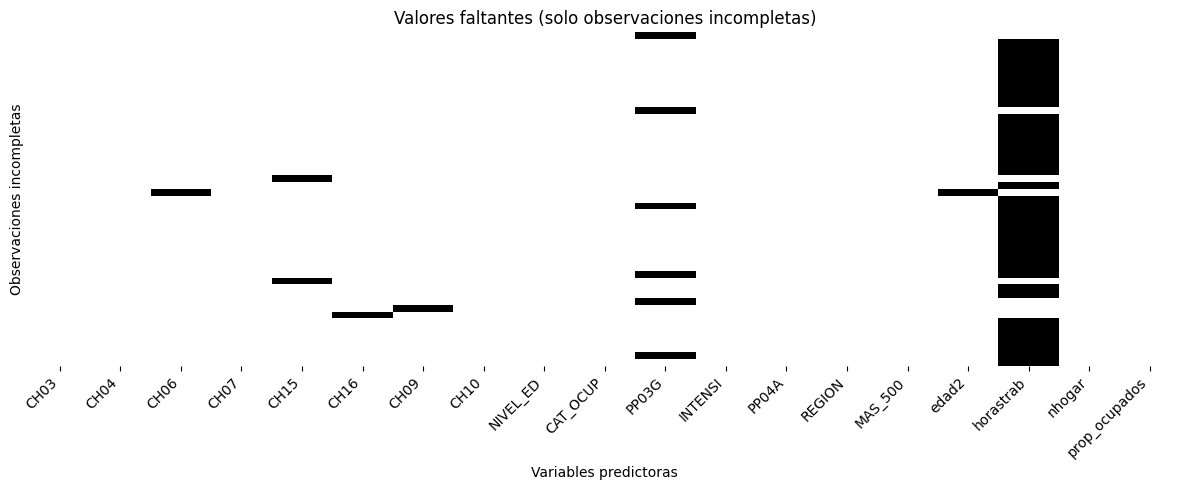

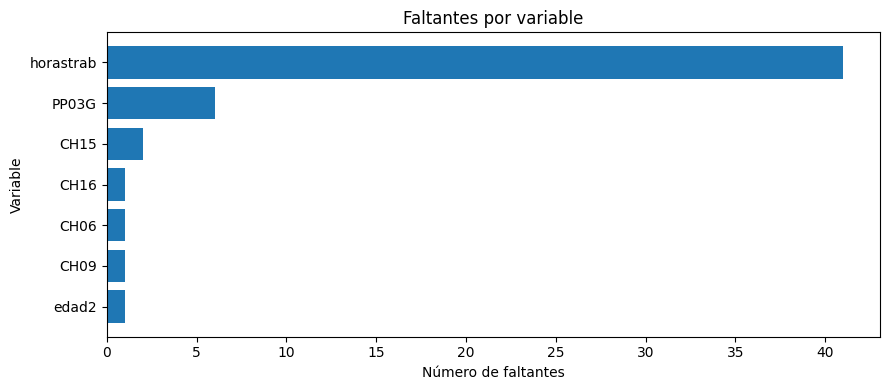

In [37]:
# ============================================================
# 3.1 FALTANTES DE LA MATRIZ ORIGINAL
# ============================================================
from scipy.stats import ttest_ind

X_original = datos_indiv[variables_x].copy()
y_original = datos_indiv["informal"].copy()

tabla_faltantes = pd.DataFrame({
    "N_faltantes": X_original.isna().sum(),
    "Porcentaje": 100 * X_original.isna().mean()
}).sort_values("N_faltantes", ascending=False)

display(tabla_faltantes.round(3))
print("Filas con al menos un faltante:", X_original.isna().any(axis=1).sum())

# Heatmap legible de casos con faltantes
X_faltantes = X_original.loc[X_original.isna().any(axis=1)]
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(X_faltantes.isna(), cmap="Greys", cbar=False, yticklabels=False, ax=ax)
ax.set(title="Valores faltantes (solo observaciones incompletas)",
       xlabel="Variables predictoras", ylabel="Observaciones incompletas")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(join(b_path_figr, "heatmap_faltantes_zoom.png"), dpi=300, bbox_inches="tight")
plt.show()

# Recuento por variable
fig, ax = plt.subplots(figsize=(9, 4))
faltantes = tabla_faltantes.loc[tabla_faltantes["N_faltantes"] > 0, "N_faltantes"].sort_values()
ax.barh(faltantes.index, faltantes.values)
ax.set(xlabel="Número de faltantes", ylabel="Variable", title="Faltantes por variable")
fig.tight_layout()
fig.savefig(join(b_path_figr, "faltantes_por_variable.png"), dpi=300, bbox_inches="tight")
plt.show()

tabla_faltantes.to_csv(join(b_path_tabl, "tabla_faltantes.csv"), encoding="utf-8-sig")

In [38]:
# ============================================================
# 3.2 CASOS COMPLETOS Y DIFERENCIA DE MEDIAS
# ============================================================
datos_completos = datos_indiv.dropna(subset=variables_x).copy()

variables_numericas = ["CH06", "edad2", "horastrab", "nhogar", "prop_ocupados"]
variables_categoricas = [v for v in variables_x if v not in variables_numericas]

X_dummies = pd.get_dummies(datos_completos[variables_x], columns=variables_categoricas, drop_first=True, dtype=int)
y_completo = datos_completos["informal"]

resultados = []
for var in X_dummies.columns:
    formales = X_dummies.loc[y_completo == 0, var].astype(float)
    informales = X_dummies.loc[y_completo == 1, var].astype(float)
    estadistico, p = ttest_ind(informales, formales, equal_var=False)
    resultados.append({
        "Variable": var,
        "Formal": formales.mean(), "Informal": informales.mean(),
        "Diferencia": informales.mean() - formales.mean(),
        "t_stat": estadistico, "p_valor": p
    })

tabla_medias = pd.DataFrame(resultados)
tabla_medias["Significancia"] = np.select(
    [tabla_medias["p_valor"] < .01, tabla_medias["p_valor"] < .05,
     tabla_medias["p_valor"] < .10], ["***", "**", "*"], default=""
)
print("Casos completos:", len(datos_completos), "Eliminados:", len(datos_indiv)-len(datos_completos))
display(tabla_medias.round(4))
tabla_medias.to_csv(join(b_path_tabl, "tabla_diferencia_medias.csv"), index=False, encoding="utf-8-sig")

Casos completos: 19511 Eliminados: 49


,Variable,Formal,Informal,Diferencia,t_stat,p_valor,Significancia
0,CH06,43.4791,39.4016,-4.0775,-21.3956,0.0000,***
1,edad2,2033.6093,1754.0696,-279.5397,-16.6095,0.0000,***
2,horastrab,36.5339,33.3518,-3.1822,-11.7360,0.0000,***
3,nhogar,3.2992,3.8770,0.5777,22.0586,0.0000,***
4,prop_ocupados,0.6483,0.6270,-0.0214,-5.6862,0.0000,***
5,CH03_2,0.2456,0.2001,-0.0455,-7.6338,0.0000,***
6,CH03_3,0.1601,0.2961,0.1360,22.5735,0.0000,***
7,CH03_4,0.0122,0.0220,0.0098,5.1879,0.0000,***
8,CH03_5,0.0071,0.0202,0.0131,7.6843,0.0000,***
9,CH03_6,0.0046,0.0055,0.0009,0.8920,0.3724,


### 3.3. Presentación de la tabla de diferencias de medias en LaTeX

Se conserva una tabla **completa** de diferencias de medias para las columnas numéricas y las categorías codificadas como indicadores (anexo), y se construye otra **resumida** para el cuerpo del informe. La selección de filas de la tabla resumida se hace por relevancia económica, **no por significancia estadística**. En las variables binarias, las medias representan proporciones. Se utilizan pruebas *t* de Welch; sus valores p son exploratorios y no corrigen el diseño muestral complejo de la EPH.

Los archivos `.tex` se guardan en `B_Outputs/B_Table` (según la ruta definida al inicio). Se emplea punto de miles y coma decimal, y los valores p menores que 0,001 se presentan como tales.

In [39]:
# Etiquetas legibles para las variables principales del modelo ACTUAL
etiquetas = {
    "CH06": "Edad (años)",
    "edad2": "Edad al cuadrado",
    "horastrab": "Horas trabajadas por semana",
    "nhogar": "Integrantes del hogar",
    "prop_ocupados": "Proporción de ocupados del hogar",
    "CH04_2": "Mujer",
    "CH03_2": "Cónyuge o pareja (vs. jefe/a)",
    "NIVEL_ED_6": "Superior universitario completo (vs. categoría base)",
    "CAT_OCUP_3": "Asalariado (vs. patrón)",
    "MAS_500_S": "Aglomerado de 500.000 o más habitantes"
}

# Seleccionar sin asumir que las variables de la OTRA especificación existen
principales = [v for v in etiquetas if v in tabla_medias["Variable"].values]
if len(principales) != len(etiquetas):
    print("No encontradas en la matriz:", set(etiquetas) - set(principales))

# Orden y etiquetas de columnas para el informe
columnas = {
    "Formal": "Formales", "Informal": "Informales", "Diferencia": "Diferencia",
    "t_stat": "t", "p_valor": "p-valor"
}

# Nunca redondear antes de formatear: tabla_medias conserva precisión
base_medias = tabla_medias.set_index("Variable")[list(columnas)].rename(columns=columnas)
tabla_principal = base_medias.loc[principales].rename(index=etiquetas)
tabla_anexo = base_medias.rename(index=lambda v: etiquetas.get(v, v))

# Separadores regionales: miles con punto, decimales con coma
def formato_es(valor, decimales=3):
    if pd.isna(valor):
        return "--"
    s = f"{valor:,.{decimales}f}"
    return s.replace(",", "#").replace(".", ",").replace("#", ".")


def preparar_latex(tabla):
    res = tabla.copy().astype(object)
    for col in tabla.columns:
        if col == "p-valor":
            res[col] = tabla[col].map(
                lambda p: "\\textless{}0,001" if pd.notna(p) and p < 0.001
                else formato_es(p, 3)
            )
        elif col == "t":
            res[col] = tabla[col].map(lambda v: formato_es(v, 2))
        else:
            res[col] = tabla[col].map(lambda v: formato_es(v, 3))
    return res

# escape=False es necesario para que LaTeX interprete \textless; las etiquetas
# se escapan manualmente si contienen caracteres especiales, por ejemplo guiones bajos.
def escapar_etiqueta(et):
    return str(et).replace("_", "\\_").replace("%", "\\%")

def exportar_tabla(tabla, nombre, etiqueta, titulo):
    formateada = preparar_latex(tabla)
    formateada.index = formateada.index.map(escapar_etiqueta)
    formateada.to_latex(
        join(b_path_tabl, nombre),
        escape=False,
        column_format="l" + "r" * len(formateada.columns),
        caption=titulo, label=etiqueta,
    )
    return formateada

vista_principal = exportar_tabla(
    tabla_principal,
    "tabla_diferencia_medias_resumen.tex", "tab:dif_medias_resumen",
    "Diferencias de medias entre trabajadores formales e informales (variables seleccionadas)"
)
exportar_tabla(
    tabla_anexo,
    "tabla_diferencia_medias_completa.tex", "tab:dif_medias_completa",
    "Diferencias de medias entre trabajadores formales e informales (matriz completa)"
)

print("Variables en tabla resumida:", len(tabla_principal))
print("Variables en tabla completa:", len(tabla_anexo))
display(vista_principal)
print("Nota: La diferencia se calcula como media informal menos media formal.")
print("Los p-valores no incorporan ponderaciones ni diseño muestral complejo.")


Variables en tabla resumida: 10
Variables en tabla completa: 51


,Formales,Informales,Diferencia,t,p-valor
Variable,,,,,
Edad (años),"43,479","39,402","-4,078","-21,40","\textless{}0,001"
Edad al cuadrado,"2.033,609","1.754,070","-279,540","-16,61","\textless{}0,001"
Horas trabajadas por semana,"36,534","33,352","-3,182","-11,74","\textless{}0,001"
Integrantes del hogar,"3,299","3,877","0,578","22,06","\textless{}0,001"
Proporción de ocupados del hogar,"0,648","0,627","-0,021","-5,69","\textless{}0,001"
Mujer,"0,448","0,461","0,013","1,81","0,071"
Cónyuge o pareja (vs. jefe/a),"0,246","0,200","-0,045","-7,63","\textless{}0,001"
Superior universitario completo (vs. categoría base),"0,364","0,090","-0,274","-49,22","\textless{}0,001"
Asalariado (vs. patrón),"0,808","0,596","-0,211","-32,67","\textless{}0,001"


Nota: La diferencia se calcula como media informal menos media formal.
Los p-valores no incorporan ponderaciones ni diseño muestral complejo.


## 4. Consigna 4 — Entrenamiento y prueba

Se divide aleatoriamente la muestra completa en 70 % de entrenamiento y 30 % de prueba con semilla 444, tal como exige la consigna. Las dummies se construyen de manera consistente para ambos subconjuntos; se incluye una columna `const=1`. Si luego se estima con `sklearn`, se debe quitar esta columna o configurar `fit_intercept=False` para evitar duplicar el intercepto.

In [40]:
X = X_dummies.copy()
y = y_completo.copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.70, random_state=444)
X_train.insert(0, "const", 1)
X_test.insert(0, "const", 1)

assert X_train.columns.equals(X_test.columns)
assert not X_train.isna().any().any() and not X_test.isna().any().any()

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)
print("Informalidad train:", y_train.value_counts(normalize=True).round(4).to_dict())
print("Informalidad test:", y_test.value_counts(normalize=True).round(4).to_dict())

# Guardar base limpia y reproducible para siguientes TPs
columnas_guardar = ["CODUSU", "NRO_HOGAR", "COMPONENTE", "informal"] + variables_x
datos_completos[columnas_guardar].to_csv(join(b_path_data, "EPH_T126_limpia.csv"), index=False, encoding="utf-8-sig")
print("Base limpia guardada.")

# ============================================================
# 4.1. DIAGNÓSTICOS PARA REGRESIÓN LOGÍSTICA Y LDA
# ============================================================
from scipy.linalg import qr

# Examinar columnas constantes / duplicadas en la muestra de entrenamiento
X_sin_intercepto = X_train.drop(columns="const")
columnas_constantes = X_sin_intercepto.columns[X_sin_intercepto.nunique() <= 1].tolist()
columnas_duplicadas = X_sin_intercepto.columns[X_sin_intercepto.T.duplicated()].tolist()

# Descomposición QR con pivoteo para detectar dependencias lineales exactas o casi exactas.
matriz = X_train.to_numpy(dtype=float)
_, R, pivotes = qr(matriz, mode="economic", pivoting=True)
diagonal = np.abs(np.diag(R))
umbral = max(matriz.shape) * np.finfo(float).eps * (diagonal.max() if len(diagonal) else 0)
rango = int((diagonal > umbral).sum())
columnas_dependientes = X_train.columns[pivotes[rango:]].tolist()

print("Columnas (incluido intercepto):", X_train.shape[1])
print("Rango numérico en train:", rango)
print("Columnas constantes:", columnas_constantes)
print("Columnas duplicadas:", columnas_duplicadas)
print("Columnas potencialmente dependientes:", columnas_dependientes)

# No eliminar predictores automáticamente: si hay dependencias se revisará la
# codificación de las categorías antes de estimar la regresión logística.


X_train: (13657, 52) y_train: (13657,)
X_test: (5854, 52) y_test: (5854,)
Informalidad train: {0: 0.5503, 1: 0.4497}
Informalidad test: {0: 0.5511, 1: 0.4489}
Base limpia guardada.
Columnas (incluido intercepto): 52
Rango numérico en train: 52
Columnas constantes: []
Columnas duplicadas: []
Columnas potencialmente dependientes: []
